In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

CLEAN_DIR = Path(r"C:\Users\anthony\Desktop\MEGAMART_ETL\data\CLEANED_OUTPUT")
print("Folder exists:", CLEAN_DIR.exists())
print("Files in folder:", [f.name for f in CLEAN_DIR.iterdir()])

Folder exists: True
Files in folder: ['Dim_Date_Final.csv', 'Dim_Store_Final.csv', 'Dim_Supplier_Final.csv', 'Fact_Sales_Final.csv']


In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

CLEAN_DIR = Path(r"C:\Users\anthony\Desktop\MEGAMART_ETL\data\CLEANED_OUTPUT")

date_df = pd.read_csv(CLEAN_DIR / "Dim_Date_Final.csv")
store_df = pd.read_csv(CLEAN_DIR / "Dim_Store_Final.csv")
supplier_df = pd.read_csv(CLEAN_DIR / "Dim_Supplier_Final.csv")
sales_df = pd.read_csv(CLEAN_DIR / "Fact_Sales_Final.csv")

for name, df in [
    ("Dim_Date_Final", date_df),
    ("Dim_Store_Final", store_df),
    ("Dim_Supplier_Final", supplier_df),
    ("Fact_Sales_Final", sales_df),
]:
    print(f"=== {name} ({len(df)} rows) ===")
    print(list(df.columns))

=== Dim_Date_Final (476 rows) ===
['full_date', 'date_key', 'day_of_week', 'day_name', 'week_of_year', 'month_name', 'quarter', 'fiscal_year', 'is_weekend', 'is_holiday', 'holiday_name', 'season_name', 'is_hurricane_season']
=== Dim_Store_Final (542 rows) ===
['store_code', 'store_name', 'address', 'parish', 'city', 'region', 'store_type', 'opening_date', 'square_footage', 'store_status', 'closure_date', 'manager_name']
=== Dim_Supplier_Final (542 rows) ===
['supplier_key', 'supplier_id', 'supplier_name', 'supplier_type', 'country', 'contact_name', 'phone', 'email', 'lead_time_days', 'supplier_rating']
=== Fact_Sales_Final (1200 rows) ===
['date_key', 'time_key', 'product_key', 'store_key', 'customer_key', 'employee_key', 'promotion_key', 'payment_method_key', 'transaction_id', 'quantity_sold', 'unit_price', 'discount_amount', 'sales_amount', 'cost_amount', 'gross_profit', 'gct_amount']


In [4]:
print("s_work store-like cols:", [c for c in s_work.columns if "store" in c.lower()])
print("store_df cols:", list(store_df.columns))

s_work store-like cols: ['store_key']
store_df cols: ['store_code', 'store_name', 'address', 'parish', 'city', 'region', 'store_type', 'opening_date', 'square_footage', 'store_status', 'closure_date', 'manager_name']


In [5]:
print("s_work store_key unique:", sorted(s_work["store_key"].dropna().unique())[:15])
print("store_df store_code unique:", list(st_work["store_code"].dropna().unique())[:15])
print("store_df len:", len(st_work))

s_work store_key unique: [np.int64(1)]


NameError: name 'st_work' is not defined

In [6]:
print("s_work store_key unique:", sorted(s_work["store_key"].dropna().unique())[:15])
print("store_df store_code unique:", list(store_df["store_code"].dropna().unique())[:15])
print("store_df len:", len(store_df))

s_work store_key unique: [np.int64(1)]
store_df store_code unique: ['MM-JM-101', 'MM-JM-102', 'MM-JM-103', 'MM-JM-104', 'MM-JM-105', 'MM-JM-106', 'MM-JM-107', 'MM-JM-108', 'MM-JM-109', 'MM-JM-110', 'MM-JM-111', 'MM-JM-112', 'MM-JM-113', 'MM-JM-114', 'MM-JM-115']
store_df len: 542


,Total Sales,Total Gross Profit,Total GCT (15%),Avg Sales per Row,Line Items
0,60000.0,24000.0,9000.0,50.0,1200


,,,,line_items,total_sales,total_gross_profit,total_gct,gross_margin_pct
store_code,store_name,parish,region,,,,,
MM-JM-101,MegaMart May Pen #1,Clarendon,Central,1200,60000.0,24000.0,9000.0,40.0


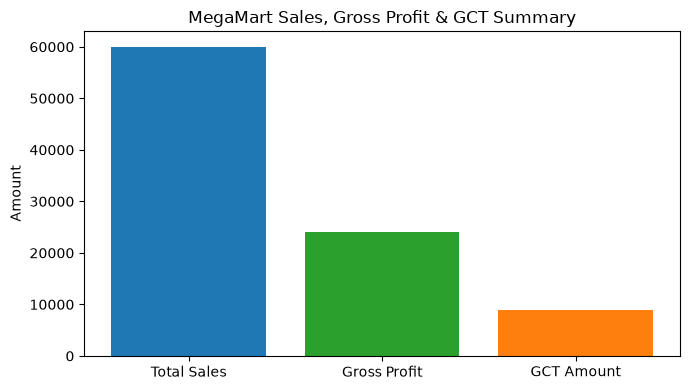

In [7]:
def normalize_date_key(s):
    if np.issubdtype(s.dtype, np.number):
        return s.astype(int)
    dt = pd.to_datetime(s, errors="coerce")
    return dt.dt.strftime("%Y%m%d").astype(int)

s_work = sales_df.copy()
s_work.columns = s_work.columns.str.strip()
s_work["date_key_norm"] = normalize_date_key(s_work["date_key"])

d_work = date_df.copy()
d_work.columns = d_work.columns.str.strip()
if "date_key" in d_work.columns:
    d_work["date_key_norm"] = normalize_date_key(d_work["date_key"])
elif "full_date" in d_work.columns:
    d_work["date_key_norm"] = normalize_date_key(d_work["full_date"])

st_work = store_df.copy().reset_index(drop=True)
st_work.columns = st_work.columns.str.strip()
st_work["_store_key_1based"] = st_work.index + 1

merged_sales = (
    s_work.merge(d_work, on="date_key_norm", how="left", suffixes=("", "_date"))
          .merge(st_work, left_on="store_key", right_on="_store_key_1based", how="left", suffixes=("", "_store"))
)

# Overall KPIs for screenshot
kpis = pd.DataFrame({
    "Total Sales": [merged_sales["sales_amount"].sum()],
    "Total Gross Profit": [merged_sales["gross_profit"].sum()],
    "Total GCT (15%)": [merged_sales["gct_amount"].sum()],
    "Avg Sales per Row": [merged_sales["sales_amount"].mean()],
    "Line Items": [len(merged_sales)],
}).round(2)
display(kpis)

# Store & Parish breakdown for the mapped store(s)
group_cols = [c for c in ["store_code", "store_name", "parish", "region"] if c in merged_sales.columns]
if group_cols:
    store_perf = (
        merged_sales.groupby(group_cols, dropna=False)
        .agg(
            line_items=("sales_amount", "count"),
            total_sales=("sales_amount", "sum"),
            total_gross_profit=("gross_profit", "sum"),
            total_gct=("gct_amount", "sum"),
        )
        .assign(
            gross_margin_pct=lambda x: np.where(
                x["total_sales"] > 0, (x["total_gross_profit"] / x["total_sales"]) * 100, 0
            )
        )
        .round(2)
    )
    display(store_perf)

# Sales & Gross Profit comparison chart
fig, ax = plt.subplots(figsize=(7, 4))
totals = [
    merged_sales["sales_amount"].sum(),
    merged_sales["gross_profit"].sum(),
    merged_sales["gct_amount"].sum(),
]
ax.bar(["Total Sales", "Gross Profit", "GCT Amount"], totals, color=["#1f77b4", "#2ca02c", "#ff7f0e"])
ax.set_title("MegaMart Sales, Gross Profit & GCT Summary")
ax.set_ylabel("Amount")
plt.tight_layout()
plt.show()

,line_items,total_sales,avg_sales,total_gross_profit
is_hurricane_season,,,,
0,646,32300.0,50.0,12920.0
1,554,27700.0,50.0,11080.0


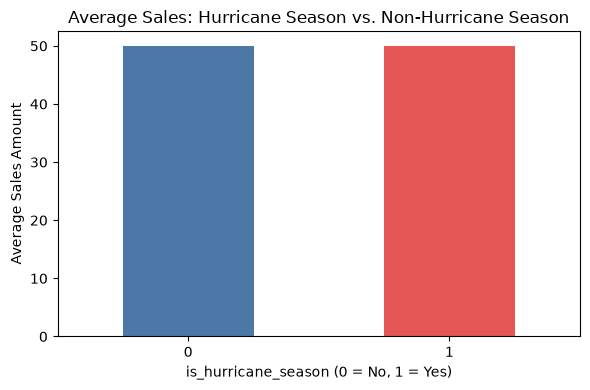

,line_items,total_sales,avg_sales,total_gross_profit
month_name,,,,
March,138,6900.0,50.0,2760.0
August,134,6700.0,50.0,2680.0
July,129,6450.0,50.0,2580.0
May,118,5900.0,50.0,2360.0
April,115,5750.0,50.0,2300.0
June,114,5700.0,50.0,2280.0
February,102,5100.0,50.0,2040.0
January,100,5000.0,50.0,2000.0
November,74,3700.0,50.0,1480.0


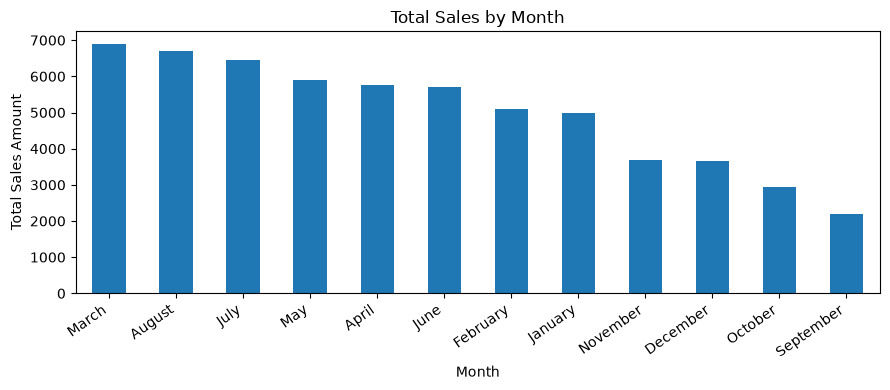

In [8]:
# Hurricane season comparison (requires is_hurricane_season in merged_sales)
hur_col = next((c for c in merged_sales.columns if "hurricane" in c.lower()), None)
if hur_col:
    hur_summary = (
        merged_sales.groupby(hur_col, dropna=False)
        .agg(
            line_items=("sales_amount", "count"),
            total_sales=("sales_amount", "sum"),
            avg_sales=("sales_amount", "mean"),
            total_gross_profit=("gross_profit", "sum"),
        )
        .round(2)
    )
    display(hur_summary)

    ax = hur_summary["avg_sales"].plot(kind="bar", figsize=(6, 4), color=["#4c78a8", "#e45756"])
    ax.set_title("Average Sales: Hurricane Season vs. Non-Hurricane Season")
    ax.set_ylabel("Average Sales Amount")
    ax.set_xlabel(f"{hur_col} (0 = No, 1 = Yes)")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
else:
    print("No hurricane column found. Available date columns:", [c for c in merged_sales.columns if "date" in c.lower() or "season" in c.lower() or "month" in c.lower()])

# Monthly breakdown if month_name or a date column exists
month_col = next((c for c in ["month_name", "month_name_date"] if c in merged_sales.columns), None)
if month_col:
    month_summary = (
        merged_sales.groupby(month_col, dropna=False)
        .agg(
            line_items=("sales_amount", "count"),
            total_sales=("sales_amount", "sum"),
            avg_sales=("sales_amount", "mean"),
            total_gross_profit=("gross_profit", "sum"),
        )
        .sort_values("total_sales", ascending=False)
        .round(2)
    )
    display(month_summary)

    ax = month_summary["total_sales"].plot(kind="bar", figsize=(9, 4), color="#1f77b4")
    ax.set_title("Total Sales by Month")
    ax.set_ylabel("Total Sales Amount")
    ax.set_xlabel("Month")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

Supplier columns: ['supplier_key', 'supplier_id', 'supplier_name', 'supplier_type', 'country', 'contact_name', 'phone', 'email', 'lead_time_days', 'supplier_rating']


,supplier_count,avg_lead_days,max_lead_days,avg_rating
supplier_type,,,,
General Merchandise & Goods,237,5.46,8,4.59
IT & Office Supplies,59,5.32,8,4.59
Food & Perishables,80,5.31,8,4.62
Facilities & Maintenance,148,5.00,8,4.65
Logistics & Security,18,4.94,7,4.64


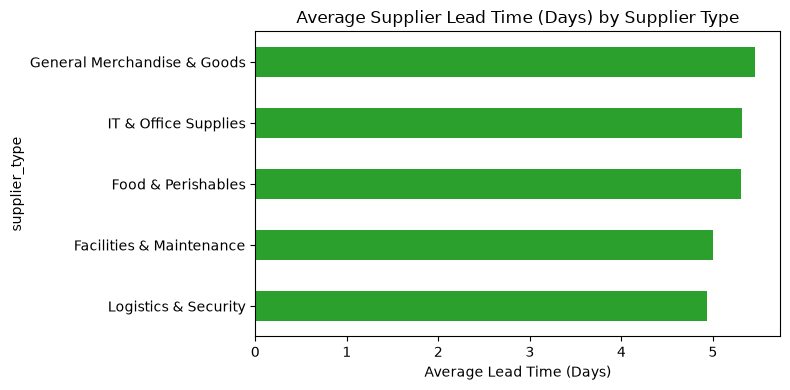

,supplier_count
country,
Jamaica,542


In [9]:
sup = supplier_df.copy()
sup.columns = sup.columns.str.strip()
print("Supplier columns:", list(sup.columns))

type_col = next((c for c in ["supplier_type", "category", "type"] if c in sup.columns), None)
lead_col = next((c for c in ["lead_time_days", "lead_days"] if c in sup.columns), None)
rating_col = next((c for c in ["supplier_rating", "rating"] if c in sup.columns), None)

if type_col and lead_col:
    agg_dict = {
        "supplier_count": (type_col, "count"),
        "avg_lead_days": (lead_col, "mean"),
        "max_lead_days": (lead_col, "max"),
    }
    if rating_col:
        agg_dict["avg_rating"] = (rating_col, "mean")

    sup_summary = (
        sup.groupby(type_col, dropna=False)
        .agg(**agg_dict)
        .sort_values("avg_lead_days", ascending=False)
        .round(2)
    )
    display(sup_summary)

    ax = sup_summary["avg_lead_days"].plot(kind="barh", figsize=(8, 4), color="#2ca02c")
    ax.invert_yaxis()
    ax.set_title("Average Supplier Lead Time (Days) by Supplier Type")
    ax.set_xlabel("Average Lead Time (Days)")
    plt.tight_layout()
    plt.show()

if "country" in sup.columns:
    display(sup["country"].value_counts(dropna=False).to_frame("supplier_count"))

,store_count,avg_sq_ft
parish,,
Kingston and St. Andrew,141,70000.0
St. Catherine,94,61017.0
Clarendon,57,43666.0
Manchester,42,40154.0
St. James,39,40155.0
St. Elizabeth,30,37630.0
Westmoreland,30,37500.0
St. Ann,29,39224.0
Portland,20,33130.0


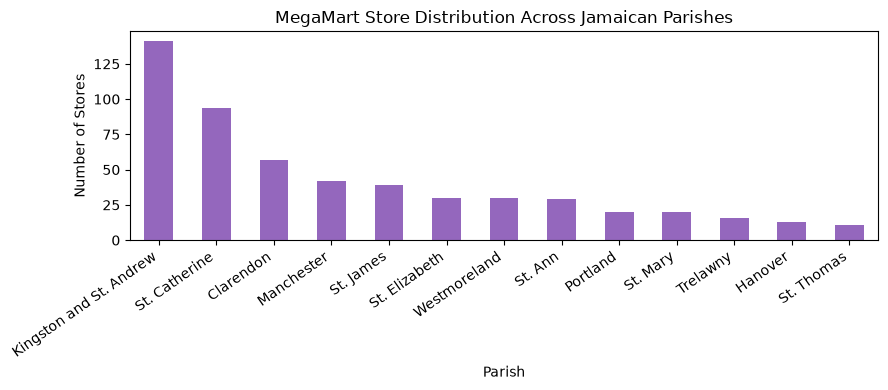

,store_count
store_type,
Express / Regional,250
Superstore,151
Flagship Hypermarket,141


In [10]:
st = store_df.copy()
st.columns = st.columns.str.strip()

# 1. Store count by Parish
if "parish" in st.columns:
    parish_dist = (
        st.groupby("parish", dropna=False)
        .agg(
            store_count=("store_code", "count"),
            avg_sq_ft=("square_footage", "mean") if "square_footage" in st.columns else ("store_code", "count"),
        )
        .sort_values("store_count", ascending=False)
        .round(2)
    )
    display(parish_dist)

    ax = parish_dist["store_count"].plot(kind="bar", figsize=(9, 4), color="#9467bd")
    ax.set_title("MegaMart Store Distribution Across Jamaican Parishes")
    ax.set_ylabel("Number of Stores")
    ax.set_xlabel("Parish")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

# 2. Store breakdown by Store Type & Status
if "store_type" in st.columns:
    type_dist = st["store_type"].value_counts(dropna=False).to_frame("store_count")
    display(type_dist)

,transactions,total_sales,avg_sales,total_discount,total_gross_profit,avg_margin_pct
discount_tier,,,,,,
Full Price,1200,60000.0,50.0,0.0,24000.0,40.0


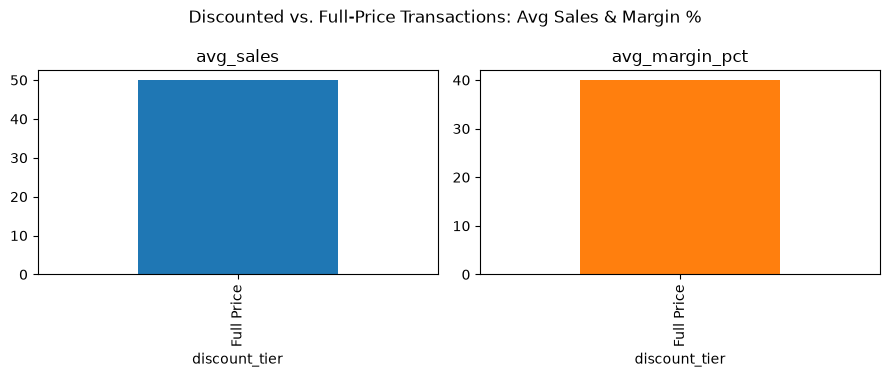

In [11]:
s_fin = sales_df.copy()
s_fin.columns = s_fin.columns.str.strip()

# Calculate per-row gross margin %
s_fin["margin_pct"] = np.where(
    s_fin["sales_amount"] > 0,
    (s_fin["gross_profit"] / s_fin["sales_amount"]) * 100,
    0,
)

# Check if discount_amount or quantity exists for deeper segmentation
has_discount = "discount_amount" in s_fin.columns
if has_discount:
    s_fin["discount_tier"] = np.where(s_fin["discount_amount"] > 0, "Discounted", "Full Price")
    disc_summary = (
        s_fin.groupby("discount_tier", dropna=False)
        .agg(
            transactions=("sales_amount", "count"),
            total_sales=("sales_amount", "sum"),
            avg_sales=("sales_amount", "mean"),
            total_discount=("discount_amount", "sum"),
            total_gross_profit=("gross_profit", "sum"),
            avg_margin_pct=("margin_pct", "mean"),
        )
        .round(2)
    )
    display(disc_summary)

    ax = disc_summary[["avg_sales", "avg_margin_pct"]].plot(kind="bar", subplots=True, layout=(1, 2), figsize=(9, 3.8), legend=False)
    plt.suptitle("Discounted vs. Full-Price Transactions: Avg Sales & Margin %")
    plt.tight_layout()
    plt.show()
else:
    # Distribution of transaction gross margin % and top-line summary
    summary_stats = s_fin[["sales_amount", "gross_profit", "gct_amount", "margin_pct"]].describe().round(2)
    display(summary_stats)

    ax = s_fin["margin_pct"].plot(kind="hist", bins=20, figsize=(8, 4), color="#17becf", edgecolor="black")
    ax.set_title("Distribution of Gross Profit Margin (%) Across Sales Transactions")
    ax.set_xlabel("Gross Profit Margin (%)")
    ax.set_ylabel("Frequency")
    plt.tight_layout()
    plt.show()